## **Import Libraries**

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

## **Load Preprocessed Data**


In [ ]:
# Load Preprocessed Dataset
from google.colab import files
uploaded = files.upload()
file = pd.read_csv('preprocessed_classification.csv')
file.head()

Saving preprocessed_classification.csv to preprocessed_classification (3).csv


,curvature,road_type_rural,road_type_urban,num_lanes_2,num_lanes_3,num_lanes_4,speed_limit_35,speed_limit_45,speed_limit_60,speed_limit_70,...,num_reported_accidents_2,num_reported_accidents_3,num_reported_accidents_4,num_reported_accidents_5,num_reported_accidents_6,num_reported_accidents_7,num_reported_accidents_8,num_reported_accidents_9,num_reported_accidents_10,accident_risk
0,0.29,True,False,True,False,False,False,False,False,True,...,False,False,False,False,False,False,False,False,False,Medium
1,0.34,False,False,False,False,False,False,False,False,False,...,False,True,False,False,False,False,False,False,False,Low
2,0.76,True,False,True,False,False,False,False,False,True,...,False,False,False,False,False,False,False,False,False,High
3,0.37,True,False,False,True,False,False,False,False,True,...,False,False,False,False,False,False,False,False,False,Medium
4,0.39,False,False,False,True,False,False,True,False,False,...,False,False,False,False,False,False,False,False,False,Low


In [ ]:
# Separate features and label
label = 'accident_risk'
X = file.drop(columns=[label])
y = file[label]

# Encode categorical labels into numerical value for XGBoost
le = LabelEncoder()
y_encoded = le.fit_transform(y)  # Low=0, Medium=1, High=2

Split Dataset

In [ ]:
# Split Dataset (20% Testing, 80% Training)
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded)

## **Model Development & Training (Default)**

In [ ]:
# Default Parameters
xgb_model = XGBClassifier(
    objective='multi:softmax',  # multi-class classification
    num_class=3,
    eval_metric='mlogloss',
    random_state=42
)


In [ ]:
# Model Training
xgb_model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='mlogloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None, num_class=3, ...)

In [ ]:
# Getting predicition using Test Set
y_pred = xgb_model.predict(X_test)

## **Model Evaluation**

In [ ]:
print("=== Model Evaluation Results ===\n")
acc = accuracy_score(y_test, y_pred) * 100
print(f"Accuracy: {acc: .2f}%")
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=le.classes_))


=== Model Evaluation Results ===

Accuracy:  88.04%

Confusion Matrix:
 [[ 950    0  329]
 [   0 7294  955]
 [ 219  888 9360]]

Classification Report:
               precision    recall  f1-score   support

        High       0.81      0.74      0.78      1279
         Low       0.89      0.88      0.89      8249
      Medium       0.88      0.89      0.89     10467

    accuracy                           0.88     19995
   macro avg       0.86      0.84      0.85     19995
weighted avg       0.88      0.88      0.88     19995



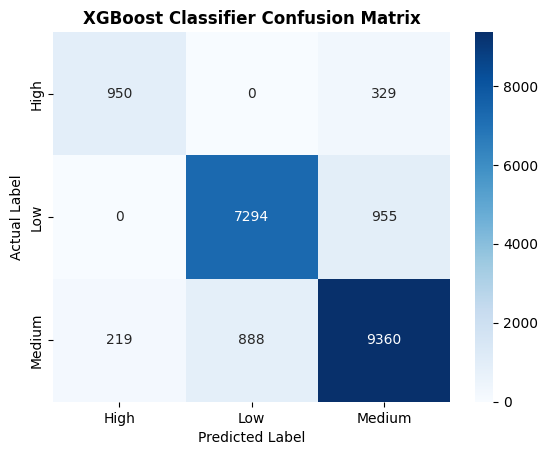

In [ ]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=le.classes_,
            yticklabels=le.classes_)

plt.title('XGBoost Classifier Confusion Matrix', fontweight = 'bold')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()


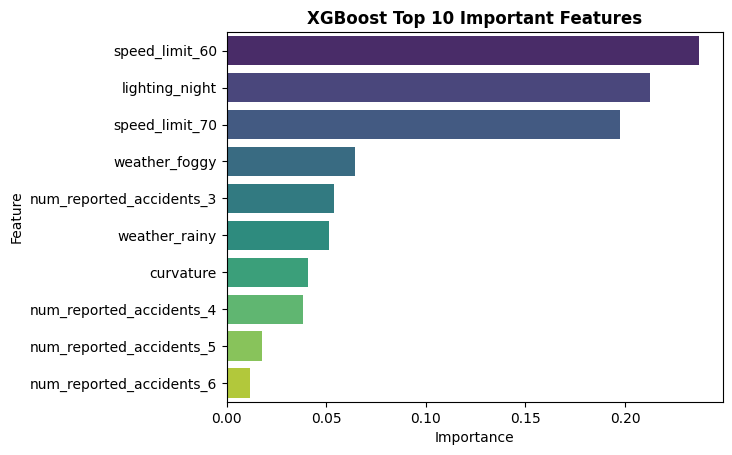

In [ ]:
# Feature importances
importances = xgb_model.feature_importances_
feature_names = X.columns

# Create DataFrame
importance_df = pd.DataFrame({'Feature': feature_names,
                              'Importance': importances})

# Sort and show top 10
top_features = importance_df.sort_values(by='Importance', ascending=False).head(10)


sns.barplot(x = 'Importance',
            y='Feature',
            data = top_features,
            palette="viridis",
            hue = 'Feature')
plt.title('XGBoost Top 10 Important Features', fontweight = 'bold')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()

## **Hyperparameter Tuning**

In [ ]:
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [4, 6, 8],
    'learning_rate': [0.01, 0.1, 0.2],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
    'gamma': [0, 1, 5],
    'min_child_weight': [1, 3, 5]
}


In [ ]:
xgb_model = XGBClassifier(
    objective='multi:softmax',  # multi-class classification
    num_class=3,
    eval_metric='mlogloss',
    use_label_encoder=False,
    random_state=42
)

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

random_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_grid,
    n_iter=30,            # number of random combinations to try
    scoring='accuracy',   # can also try 'f1_weighted' for imbalance
    cv=3,                 # 3-fold cross-validation
    verbose=2,            # see progress
    n_jobs=-1,            # use all CPU cores
    random_state=42
)

random_search.fit(X_train, y_train)

print("Best Parameters:", random_search.best_params_)
print("Best CV Accuracy: {:.2f}%".format(random_search.best_score_ * 100))


Fitting 3 folds for each of 30 candidates, totalling 90 fits


In [ ]:
best_xgb = random_search.best_estimator_
y_pred = best_xgb.predict(X_test)


In [ ]:
print("=== Model Evaluation Results ===\n")
acc = accuracy_score(y_test, y_pred) * 100
print(f"Accuracy: {acc: .2f}%")
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=le.classes_))
